# Blackbody radiation, advanced: surface temperature, heat island and drought from Landsat 8

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/blackbody_radiation_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [Blackbody radiation](https://openskylab.space/edu_viz_blackbody_radiation.html) · [česká verze](blackbody_radiation_pro_cs.ipynb)

The advanced version of the Planck's law notebook. Here you compute surface temperature from the Landsat 8 thermal band with the radiative transfer equation, i.e. with both emissivity and atmosphere, and find out which correction matters more. You then apply the result to the Prague urban heat island on two days and to the TVDI drought index from the temperature–NDVI space.

**Goal:** compute surface temperature from the radiative transfer equation and estimate the effect of emissivity and atmosphere, measure the surface urban heat island by land-cover class, and build the dry and wet edges and the TVDI index from the temperature–NDVI space.

**Data:** Landsat 8 OLI/TIRS Collection 1 Level-1 from the Google Cloud public archive: `LC08_L1TP_191025_20190626_20190705_01_T1` (26 June 2019, heat wave) and `LC08_L1TP_191025_20170519_20170525_01_T1` (19 May 2017), bands B4, B5, B10, BQA and MTL; ESA WorldCover 2021 v200 classes. A 30 × 30 km window around Prague, about 25 MB. The atmospheric parameters (transmittance, upwelling and downwelling radiance) are not downloaded: they are given as indicative values that can be changed; real values for a given day and place come for instance from the NASA calculator (Barsi et al. 2005).

**Tasks:** four. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 65 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and two scenes

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.windows import from_bounds
from pyproj import Transformer
warnings.filterwarnings("ignore")
C1, C2 = 1.191042e8, 1.4387752e4         # Planck constants for λ in µm and radiance in W·m⁻²·sr⁻¹·µm⁻¹
planck = lambda lam, T: C1 / lam**5 / (np.exp(C2 / (lam * T)) - 1)
planck_inv = lambda lam, L: C2 / (lam * np.log(C1 / (lam**5 * L) + 1))

In [3]:
SCENES = {"2019-06-26": "LC08_L1TP_191025_20190626_20190705_01_T1", "2017-05-19": "LC08_L1TP_191025_20170519_20170525_01_T1"}   # ◀ parameter: two scenes (heat wave, spring)
LON, LAT, HALF = 14.45, 50.08, 15000      # ◀ parameter: window centre and half width (m)
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2)
x0, y0 = Transformer.from_crs(4326, 32633, always_xy=True).transform(LON, LAT)
x0, y0 = round(x0 / 30) * 30, round(y0 / 30) * 30

def scene_data(scene):
    base = f"https://storage.googleapis.com/gcp-public-data-landsat/LC08/01/191/025/{scene}/{scene}"
    mtl = {k.strip(): v.strip().strip('"') for k, v in (l.split(" = ") for l in requests.get(base + "_MTL.txt", timeout=60).text.splitlines() if " = " in l)}
    out = {"mtl": mtl}
    for b in ["4", "5", "10", "QA"]:
        with rasterio.Env(**ENV), rasterio.open(f"/vsicurl/{base}_B{b}.TIF") as r:
            w = from_bounds(x0 - HALF, y0 - HALF, x0 + HALF, y0 + HALF, r.transform).round_offsets().round_lengths()
            out[b] = r.read(1, window=w).astype(float); out["transform"] = r.window_transform(w)
    sun = np.sin(np.radians(float(mtl["SUN_ELEVATION"])))
    red, nir = [(float(mtl[f"REFLECTANCE_MULT_BAND_{b}"]) * out[str(b)] + float(mtl[f"REFLECTANCE_ADD_BAND_{b}"])) / sun for b in (4, 5)]
    out["ndvi"] = (nir - red) / (nir + red)
    out["L10"] = float(mtl["RADIANCE_MULT_BAND_10"]) * out["10"] + float(mtl["RADIANCE_ADD_BAND_10"])
    out["BT"] = float(mtl["K2_CONSTANT_BAND_10"]) / np.log(float(mtl["K1_CONSTANT_BAND_10"]) / out["L10"] + 1)
    qa = out["QA"].astype(int)
    out["ok"] = ((qa >> 4) & 1 == 0) & ((qa >> 7) & 3 < 3) & (qa > 1)
    return out

S = {day: scene_data(sc) for day, sc in SCENES.items()}
grid = S[next(iter(S))]["transform"]; shape = S[next(iter(S))]["BT"].shape
wc = np.zeros(shape, np.uint8)
with rasterio.Env(**ENV), rasterio.open("/vsicurl/" + WORLDCOVER) as r:
    reproject(rasterio.band(r, 1), wc, dst_transform=grid, dst_crs="EPSG:32633", resampling=Resampling.mode)
CLASSES = {10: "forest", 30: "grassland", 40: "cropland", 50: "built-up", 80: "water"}
for day, s in S.items():
    print(f"{day}: {s['mtl']['SCENE_CENTER_TIME'][:8]} UTC, sun elevation {float(s['mtl']['SUN_ELEVATION']):.1f}°, clear pixels {s['ok'].mean():.1%}, "
          f"B10 brightness temperature median {np.median(s['BT'][s['ok']]) - 273.15:.1f} °C")

2019-06-26: 09:50:52 UTC, sun elevation 59.8°, clear pixels 99.9%, B10 brightness temperature median 31.6 °C
2017-05-19: 09:50:28 UTC, sun elevation 57.0°, clear pixels 100.0%, B10 brightness temperature median 26.2 °C


## 2. Surface temperature from the radiative transfer equation

The sensor above the atmosphere measures L = τ · [ε · B(Ts) + (1 − ε) · L↓] + L↑: the surface emission attenuated by the atmosphere, plus reflected sky radiation and the emission of the atmosphere itself. We solve the equation for Ts. Emissivity is estimated from NDVI as in the basic version; the atmospheric parameters τ, L↑ and L↓ are indicative values for a humid summer atmosphere.

In [4]:
LAM10 = 10.9
TAU, L_UP, L_DOWN = 0.80, 1.6, 2.7        # ◀ parameter: atmospheric transmittance and upwelling and downwelling radiance (W·m⁻²·sr⁻¹·µm⁻¹), indicative summer values

def emissivity(ndvi, wc):
    """Emissivity from NDVI thresholds (Sobrino et al. 2004), water from WorldCover."""
    pv = np.clip((ndvi - 0.2) / (0.5 - 0.2), 0, 1) ** 2
    eps = np.where(ndvi < 0.2, 0.97, np.where(ndvi > 0.5, 0.99, 0.97 + 0.02 * pv))
    return np.where(wc == 80, 0.991, eps)

def lst(L, eps, tau=TAU, l_up=L_UP, l_down=L_DOWN):
    """Radiative transfer equation: L_sensor = τ · [ε · B(Ts) + (1 − ε) · L↓] + L↑, solved for Ts."""
    B = (L - l_up - tau * (1 - eps) * l_down) / (tau * eps)
    return planck_inv(LAM10, B)

for s in S.values():
    s["eps"] = emissivity(s["ndvi"], wc)
    s["LST_eps"] = lst(s["L10"], s["eps"], tau=1.0, l_up=0.0, l_down=0.0)      # emissivity only, no atmosphere
    s["LST"] = lst(s["L10"], s["eps"])
day = next(iter(S)); s = S[day]
rows = {name: {"brightness temperature (°C)": np.median(s["BT"][s["ok"] & (wc == c)]) - 273.15,
               "emissivity only (°C)": np.median(s["LST_eps"][s["ok"] & (wc == c)]) - 273.15,
               "with atmosphere (°C)": np.median(s["LST"][s["ok"] & (wc == c)]) - 273.15} for c, name in CLASSES.items()}
sens = {tau: np.median(lst(s["L10"], s["eps"], tau=tau)[s["ok"]]) - 273.15 for tau in (0.70, 0.75, 0.80, 0.85, 0.90)}
print(f"{day}: median LST by τ:", {k: round(v, 1) for k, v in sens.items()})
pd.DataFrame(rows).T.round(1)

2019-06-26: median LST by τ: {0.7: np.float64(45.7), 0.75: np.float64(40.6), 0.8: np.float64(35.9), 0.85: np.float64(31.6), 0.9: np.float64(27.7)}


,brightness temperature (°C),emissivity only (°C),with atmosphere (°C)
forest,31.2,31.8,35.3
grassland,32.6,33.2,37.0
cropland,30.6,31.2,34.6
built-up,34.8,36.4,40.4
water,28.0,28.4,31.3


> **✏️ Task 1.** By how many degrees does the emissivity correction shift the temperature, and by how many the atmospheric correction? How much does the median temperature change when τ changes by 0.05? What does this mean for the accuracy of surface temperature when you do not know the atmospheric parameters for the day?

*Your answer:* 

## 3. The surface urban heat island

We compare the surface temperature of built-up land with the surrounding farmland and forest on two days. The same atmospheric parameters are used for both days, which is a simplification: the atmosphere in May 2017 differed from the 2019 heat wave.

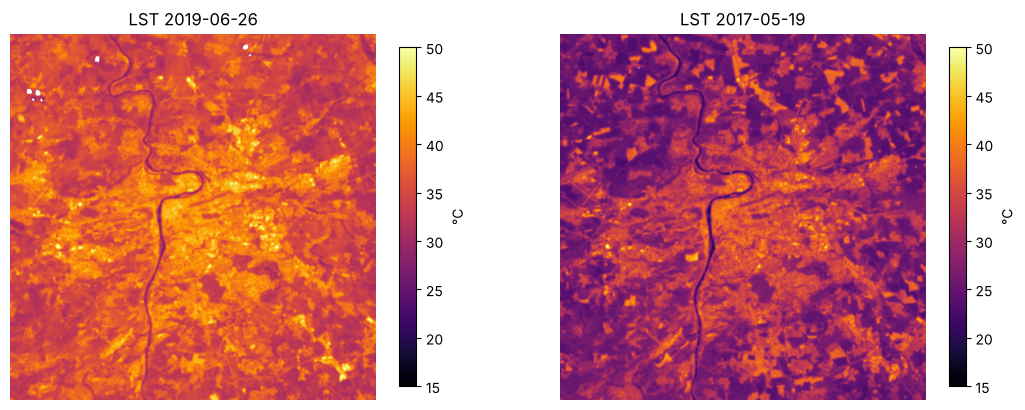

,2019-06-26,2017-05-19
forest,35.3,28.9
grassland,37.0,29.9
cropland,34.6,26.0
built-up,40.4,34.6
water,31.3,24.6
heat island: built-up − cropland,5.8,8.6
heat island: built-up − forest,5.1,5.7


In [5]:
fig, ax = plt.subplots(1, len(S), figsize=(6.5 * len(S), 5.5))
rows = {}
for a, (day, s) in zip(ax, S.items()):
    im = a.imshow(np.where(s["ok"], s["LST"] - 273.15, np.nan), cmap="inferno", vmin=15, vmax=50); a.set_title(f"LST {day}"); a.axis("off")
    fig.colorbar(im, ax=a, shrink=0.8, label="°C")
    med = {name: np.median(s["LST"][s["ok"] & (wc == c)]) - 273.15 for c, name in CLASSES.items()}
    med["heat island: built-up − cropland"] = med["built-up"] - med["cropland"]
    med["heat island: built-up − forest"] = med["built-up"] - med["forest"]
    rows[day] = med
plt.show()
pd.DataFrame(rows).round(1)

> **✏️ Task 2.** On which day is the difference between built-up land and cropland larger, and why, given that the heat wave was in June 2019? Why does the built-up minus forest difference change less between the days? How would the heat island change at night (remember thermal inertia)?

*Your answer:* 

## 4. Temperature–NDVI space and the TVDI drought index

In a plot of surface temperature against NDVI the pixels form a triangle or trapezoid. The upper, dry edge joins the warmest pixels at each NDVI (surfaces with no water to evaporate), the lower, wet edge the coolest. TVDI = (Ts − Ts_wet) / (Ts_dry(NDVI) − Ts_wet) lies between 0 (wet) and 1 (dry) (Sandholt et al. 2002). We compute it for grassland and cropland.

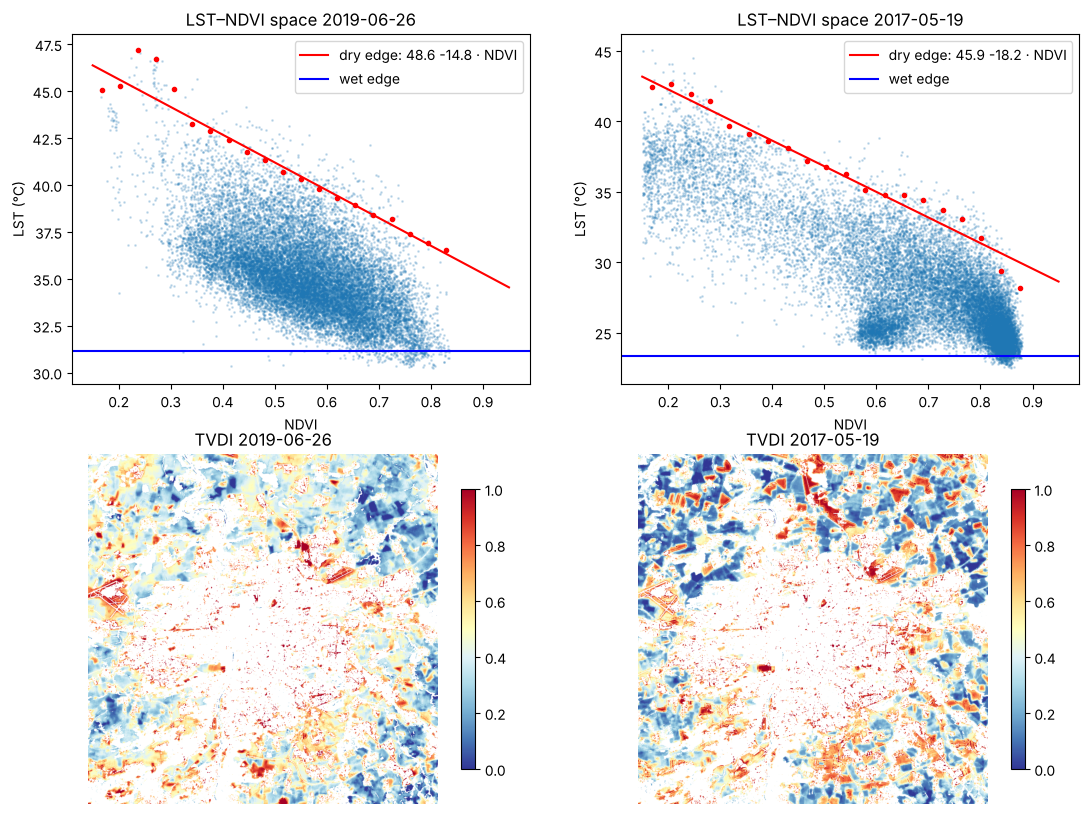

,2019-06-26,2017-05-19
grassland,0.64,0.63
cropland,0.38,0.31
dry edge slope (K per 1 NDVI),-14.79,-18.18


In [6]:
NBINS = 20                                 # ◀ parameter: number of NDVI bins for finding the dry edge
land = np.isin(wc, [30, 40])                # grassland and cropland: TVDI is used mainly for farmland

def tvdi(s):
    m = s["ok"] & land & (s["ndvi"] > 0.15)
    nd, ts = s["ndvi"][m], s["LST"][m]
    edges = np.linspace(0.15, nd.max(), NBINS + 1); k = np.digitize(nd, edges)
    mid = np.array([(edges[i - 1] + edges[i]) / 2 for i in range(1, NBINS + 1) if (k == i).sum() > 30])
    tmax = np.array([np.percentile(ts[k == i], 99) for i in range(1, NBINS + 1) if (k == i).sum() > 30])
    b, a = np.polyfit(mid[mid > 0.3], tmax[mid > 0.3], 1)        # dry edge Ts_max = a + b · NDVI
    t_wet = np.percentile(ts, 1)                                   # wet edge
    out = np.where(m, (s["LST"] - t_wet) / (a + b * s["ndvi"] - t_wet), np.nan)
    return np.clip(out, 0, 1), (a, b, t_wet, mid, tmax, nd, ts)

fig, ax = plt.subplots(2, len(S), figsize=(6.5 * len(S), 10))
summary = {}
rng = np.random.default_rng(0)
for j, (day, s) in enumerate(S.items()):
    s["TVDI"], (a, b, t_wet, mid, tmax, nd, ts) = tvdi(s)
    sel = rng.choice(len(nd), min(20000, len(nd)), replace=False)
    ax[0, j].scatter(nd[sel], ts[sel] - 273.15, s=1, alpha=0.2)
    xx = np.linspace(0.15, 0.95, 10)
    ax[0, j].plot(xx, a + b * xx - 273.15, "r", label=f"dry edge: {a - 273.15:.1f} {b:+.1f} · NDVI")
    ax[0, j].axhline(t_wet - 273.15, color="b", label="wet edge"); ax[0, j].plot(mid, tmax - 273.15, "ro", ms=3)
    ax[0, j].set(xlabel="NDVI", ylabel="LST (°C)", title=f"LST–NDVI space {day}"); ax[0, j].legend()
    im = ax[1, j].imshow(s["TVDI"], cmap="RdYlBu_r", vmin=0, vmax=1); ax[1, j].set_title(f"TVDI {day}"); ax[1, j].axis("off")
    fig.colorbar(im, ax=ax[1, j], shrink=0.8)
    summary[day] = {name: np.nanmedian(s["TVDI"][wc == c]) for c, name in CLASSES.items() if c in (30, 40)} | {"dry edge slope (K per 1 NDVI)": b}
plt.show()
pd.DataFrame(summary).round(2)

> **✏️ Task 3.** Why does the dry edge have a negative slope, i.e. why are dry pixels with higher NDVI cooler? On which day does cropland come out drier, and does that match what you know about spring 2017 and the 2019 heat wave? Why can the TVDI of two days not be compared directly when the edges are computed for each image separately?

*Your answer:* 

> **✏️ Task 4.** Grassland comes out drier than cropland in TVDI. Look at the map to see where grassland lies according to WorldCover (urban lawns, dry slopes, edges of built-up areas). Which assumptions of the method (the same weather across the window, only differences in moisture, not in roughness or elevation) may not hold here? Change `NBINS` and watch how sensitive the dry edge is.

*Your answer:* 

> **✏️ Extension (optional).** Look up the atmospheric parameters for Prague and both days in the NASA calculator (atmcorr.gsfc.nasa.gov), put them in place of the indicative values (separately for each day) and compare the temperatures and the heat island.

*Your answer:* 

---
### Data sources and references

- Landsat 8 OLI/TIRS Collection 1 Level-1, U.S. Geological Survey; Google Cloud public archive (`gcp-public-data-landsat`). USGS data have no use restrictions, attribution requested.
- Zanaga, D. et al. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- USGS (2019). *Landsat 8 (L8) Data Users Handbook*, version 5.0, ch. 5.
- Sobrino, J. A., Jiménez-Muñoz, J. C., Paolini, L. (2004). Land surface temperature retrieval from LANDSAT TM 5. *Remote Sensing of Environment* 90, 434–440. https://doi.org/10.1016/j.rse.2004.02.003
- Barsi, J. A., Schott, J. R., Palluconi, F. D., Hook, S. J. (2005). Validation of a web-based atmospheric correction tool for single thermal band instruments. *Proc. SPIE* 5882, 58820E. https://doi.org/10.1117/12.619990
- Sandholt, I., Rasmussen, K., Andersen, J. (2002). A simple interpretation of the surface temperature/vegetation index space for assessment of surface moisture status. *Remote Sensing of Environment* 79, 213–224. https://doi.org/10.1016/S0034-4257(01)00274-7

### How to cite

OpenSkyLab (2026). Blackbody radiation, advanced: surface temperature, heat island and drought from Landsat 8 [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/blackbody_radiation_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*